In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
# Import your custom preprocessing classes
from preprocessing import (
    dropper,
    numimputer,
    ordinalencoder,
    OHEEncoder,
    RareCategoryGrouper,
    MissingImputer,
    LogTransformer,
    CatImputer,
)

In [3]:
df=pd.read_csv("train.csv")
df.sample(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
659,660,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,3,2009,WD,Normal,167000
537,538,20,RL,NaN,12735,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnWw,NaN,0,4,2008,COD,Normal,111250
715,716,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
18,19,20,RL,66.0,13695,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,159000
1092,1093,50,RL,60.0,8400,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,136500


<Axes: >

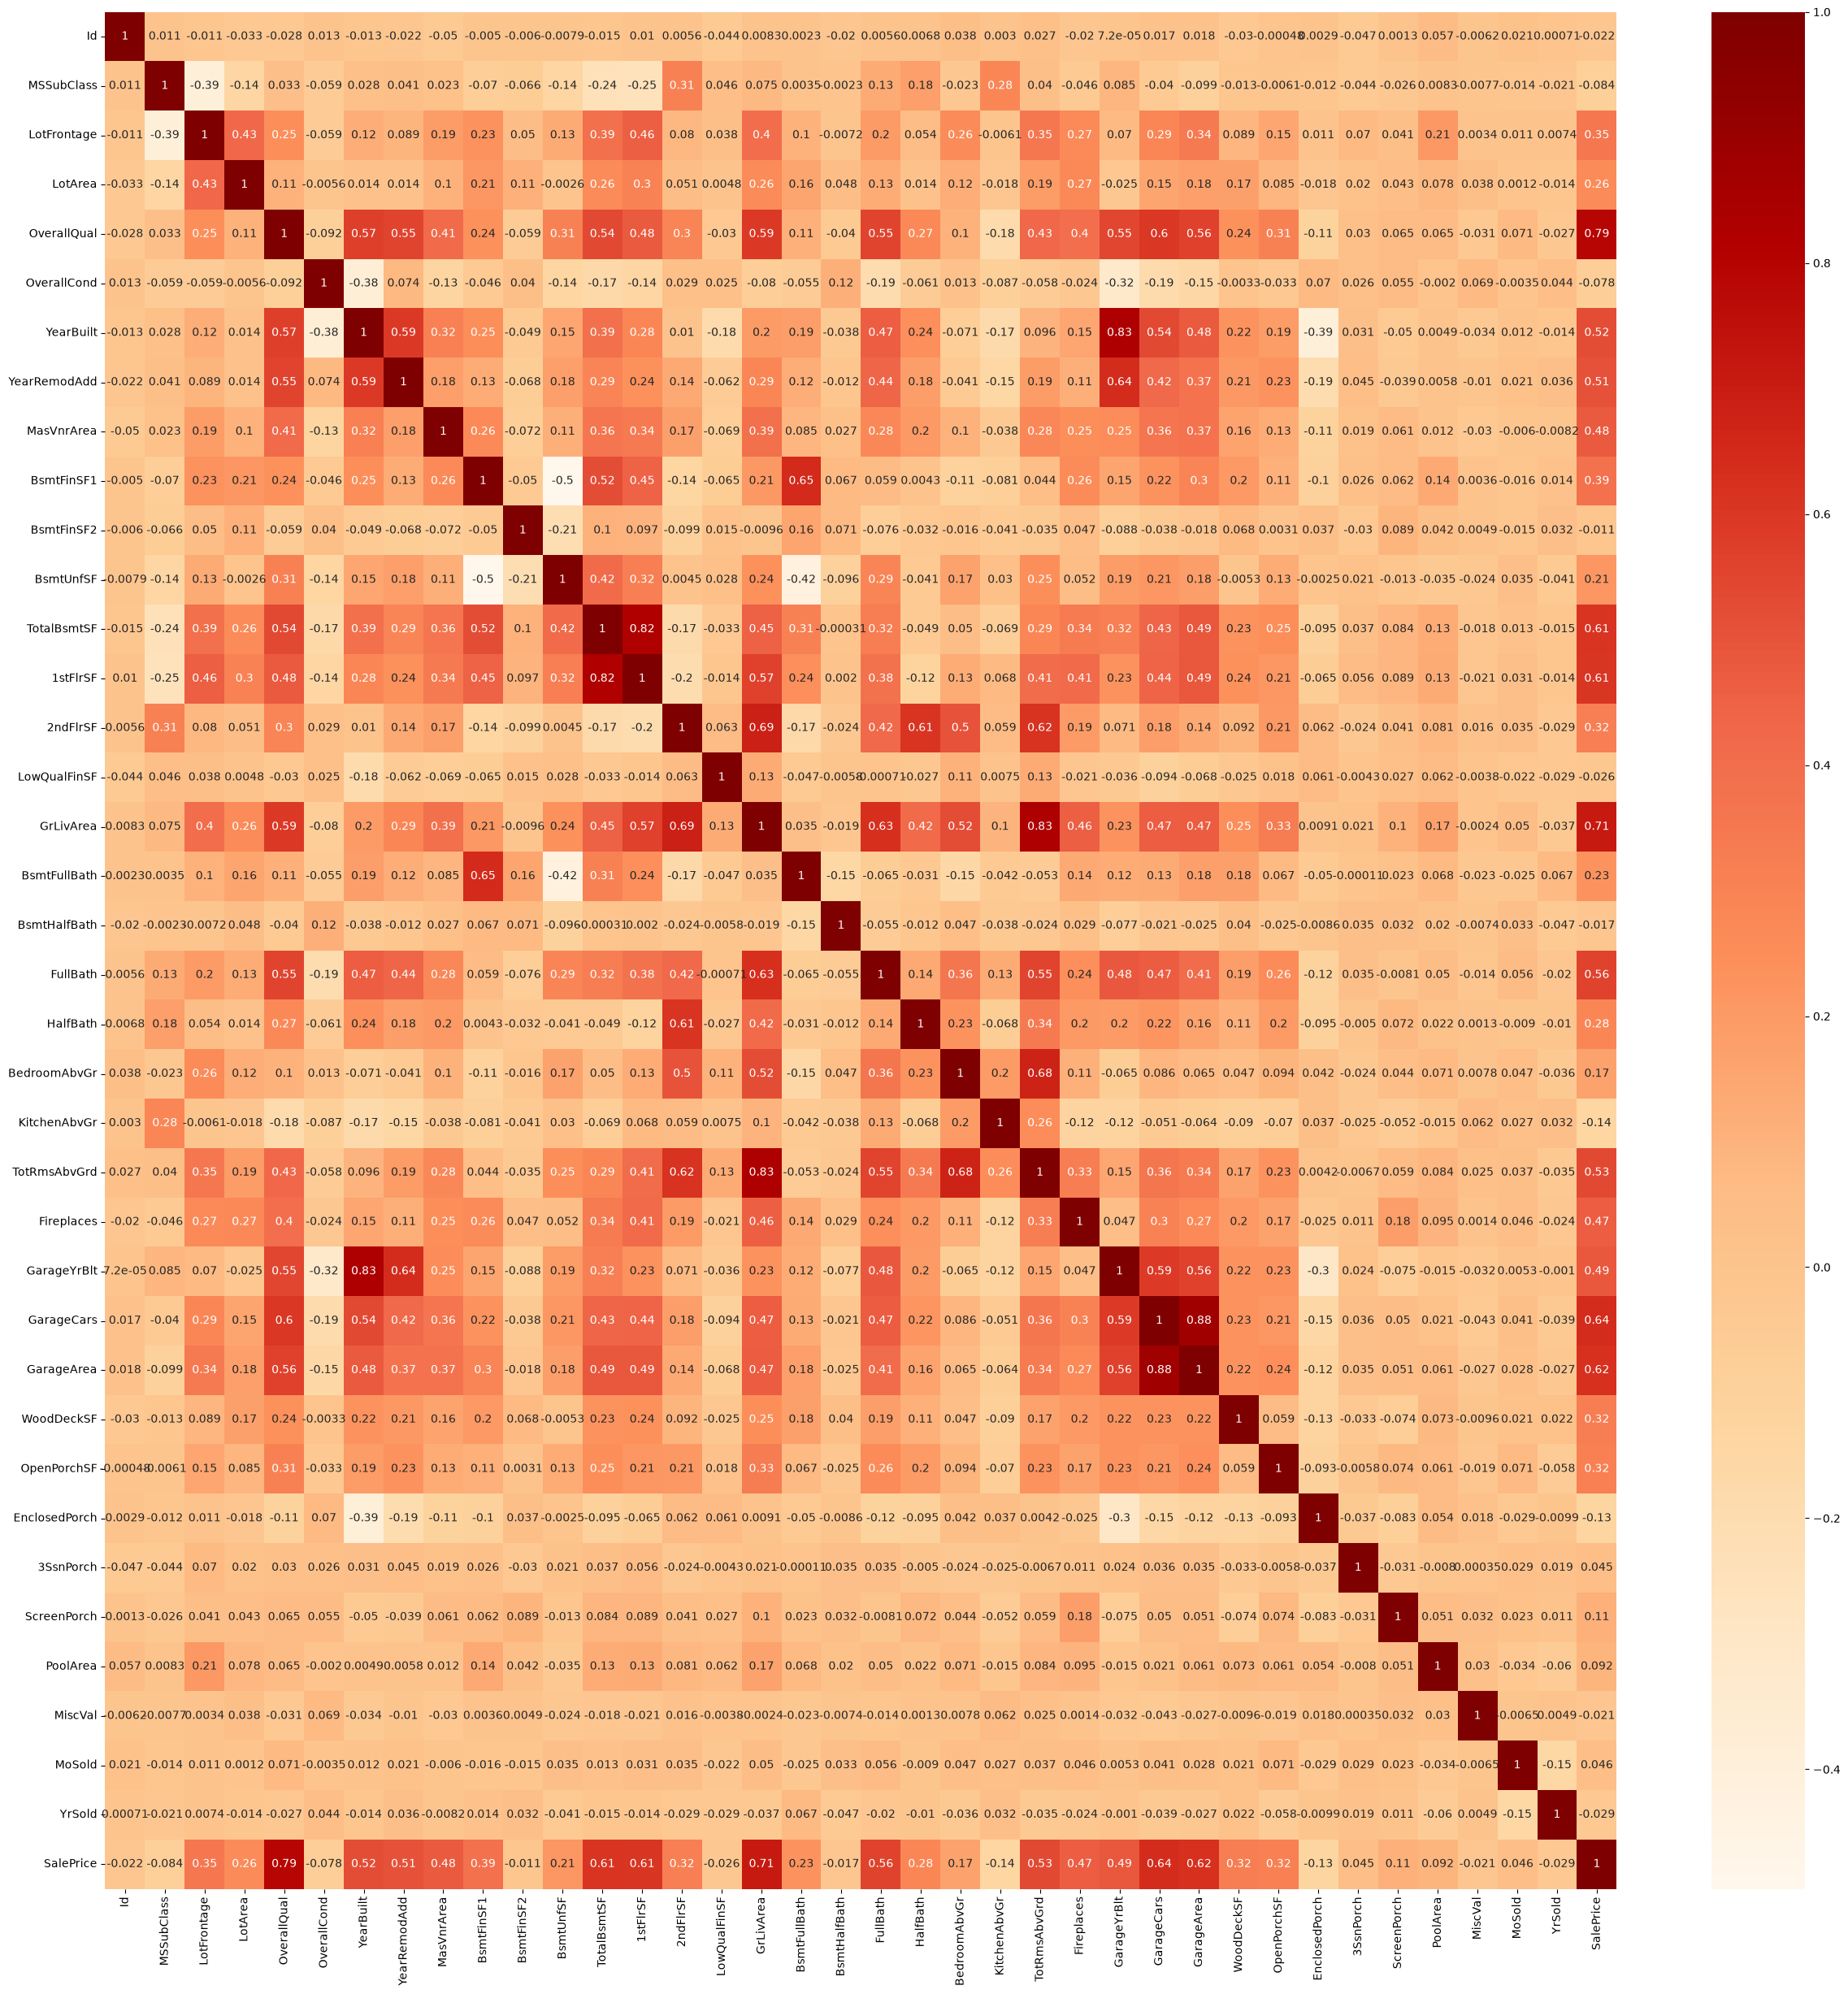

In [4]:
plt.figure(figsize=(30,30))
sns.heatmap(df.select_dtypes(include=['number']).corr(), cmap='OrRd',annot=True)

In [5]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage = missing_percentage[missing_percentage > 0]
missing_df = pd.DataFrame({
    'Missing_Percentage': missing_percentage,
    'Dtype': df[missing_percentage.index].dtypes
})
print(missing_df.sort_values(by='Missing_Percentage', ascending=False))

              Missing_Percentage    Dtype
PoolQC                 99.520548      str
MiscFeature            96.301370      str
Alley                  93.767123      str
Fence                  80.753425      str
MasVnrType             59.726027      str
FireplaceQu            47.260274      str
LotFrontage            17.739726  float64
GarageType              5.547945      str
GarageYrBlt             5.547945  float64
GarageFinish            5.547945      str
GarageQual              5.547945      str
GarageCond              5.547945      str
BsmtFinType2            2.602740      str
BsmtExposure            2.602740      str
BsmtFinType1            2.534247      str
BsmtCond                2.534247      str
BsmtQual                2.534247      str
MasVnrArea              0.547945  float64
Electrical              0.068493      str


In [6]:
x=df.drop(['SalePrice'],axis=1)
y=df['SalePrice']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
y_train = np.log1p(y_train)

array([[<Axes: title={'center': 'GarageYrBlt'}>,
        <Axes: title={'center': 'MasVnrArea'}>]], dtype=object)

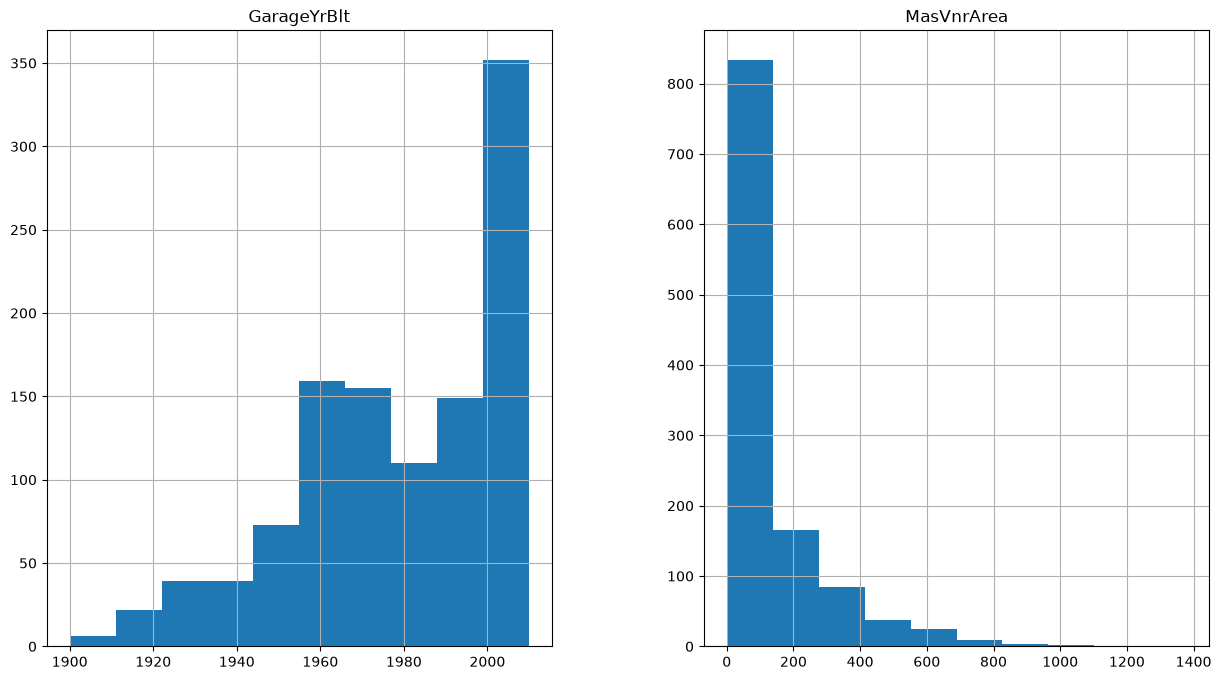

In [7]:
cols = ['GarageYrBlt','MasVnrArea']
x_train[cols].hist(figsize=(15,8))

DROPPER

In [8]:
# cols2=['PoolQC','MiscFeature','Alley','Fence','MasVnrType','FireplaceQu','LotFrontage','Id','PoolArea','3SsnPorch','MiscVal','LowQualFinSF']
# class dropper(BaseEstimator,TransformerMixin):
#     def fit(self,x,y=None):
#         return self
#     def transform(self,x):
#         x=x.drop(cols2,axis=1)
#         return x

NUMERIC IMPUTER

In [9]:
# cols1 = ['GarageYrBlt',
#     'MasVnrArea',
#     'BsmtFinSF1',
#     'BsmtFinSF2',
#     'BsmtUnfSF',
#     'TotalBsmtSF',
#     'BsmtFullBath',
#     'BsmtHalfBath',
#     'GarageCars',
#     'GarageArea']
# class numimputer(BaseEstimator,TransformerMixin):
#     def fit(self,x,y=None):
#         return self
#     def transform(self,x):
#         si=SimpleImputer(strategy="median")
#         x[cols1]=si.fit_transform(x[cols1])
#         return x

ORDINAL ENCODING

In [10]:
# bsmt_qual_order = ['Missing','Po', 'Fa', 'TA', 'Gd', 'Ex']
# bsmt_cond_order = ['Missing', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
# bsmt_exposure_order = ['Missing', 'No', 'Mn', 'Av', 'Gd']
# bsmtfintype_order = [
#     'Missing',
#     'Unf',
#     'LwQ',
#     'Rec',
#     'BLQ',
#     'ALQ',
#     'GLQ'
# ]
# # garage orders
# garage_finish_order = [
#     'Missing',
#     'Unf',
#     'RFn',
#     'Fin'
# ]
# garage_qual_cond_order = [
#     'Missing',
#     'Po',
#     'Fa',
#     'TA',
#     'Gd',
#     'Ex'
# ]
# # exterior quality orders
# exter_order = [
#     'Po',
#     'Fa',
#     'TA',
#     'Gd',
#     'Ex'
# ]
# heatingqc_order = [
#     'Po',
#     'Fa',
#     'TA',
#     'Gd',
#     'Ex'
# ]
# # kitchen quality
# kitchenqual_order = [
#     'Missing',
#     'Po',
#     'Fa',
#     'TA',
#     'Gd',
#     'Ex'
# ]
# # all ordinal columns
# cols3 = [
#     'ExterQual',
#     'ExterCond',
#     'BsmtQual',
#     'BsmtCond',
#     'BsmtExposure',
#     'BsmtFinType1',
#     'BsmtFinType2',
#     'HeatingQC',
#     'KitchenQual',
#     'GarageFinish',
#     'GarageQual',
#     'GarageCond'
# ]
# class ordinalencoder(BaseEstimator, TransformerMixin):
#     def fit(self, x, y=None):
#         self.oe = OrdinalEncoder(
#             categories=[
#                 exter_order,
#                 exter_order,
#                 bsmt_qual_order,
#                 bsmt_cond_order,
#                 bsmt_exposure_order,
#                 bsmtfintype_order,
#                 bsmtfintype_order,
#                 heatingqc_order,
#                 kitchenqual_order,
#                 garage_finish_order,
#                 garage_qual_cond_order,
#                 garage_qual_cond_order
#             ]
#         )
#         self.oe.fit(x[cols3])
#         return self
#     def transform(self, x):
#         x[cols3] = self.oe.transform(x[cols3])
#         return x      

ONE HOT ENCODING

In [11]:
# ohe_cols = [
#     'MSZoning','Street','LotShape','LandContour','Utilities',
#     'LotConfig','LandSlope','Neighborhood','Condition1',
#     'Condition2','BldgType','HouseStyle','RoofStyle',
#     'RoofMatl','Exterior1st','Exterior2nd','Foundation',
#     'Heating','CentralAir','Electrical','Functional',
#     'GarageType','PavedDrive','SaleType','SaleCondition'
# ]

# class OHEEncoder(BaseEstimator, TransformerMixin):
#     def fit(self, x, y=None):
#         self.encoder = OneHotEncoder(
#             drop='first',
#             sparse_output=False,
#             handle_unknown='ignore'
#         )
#         self.encoder.fit(x[ohe_cols])
#         return self
#     def transform(self, x):
#         encoded = self.encoder.transform(x[ohe_cols])
#         encoded_df = pd.DataFrame(
#             encoded,
#             columns=self.encoder.get_feature_names_out(ohe_cols),
#             index=x.index
#         )
#         x = x.drop(ohe_cols, axis=1)
#         x = pd.concat([x, encoded_df], axis=1)
#         return x

In [12]:
# for col in ohe_cols:
#     print(f"\n--- {col} ---")
#     print(x_train[col].value_counts(dropna=False))

In [13]:
# class RareCategoryGrouper(BaseEstimator, TransformerMixin):
#     def __init__(self):
#         self.rules = {
#             'Condition1': 10,
#             'Condition2': 10,
#             'RoofMatl': 5,
#             'Exterior1st': 5,
#             'Exterior2nd': 5,
#             'SaleType': 5,
#             'Neighborhood': 2
#         }
#     def fit(self, X, y=None):
#         self.rare_categories_ = {}

#         for col, threshold in self.rules.items():
#             counts = X[col].value_counts(dropna=True)
#             self.rare_categories_[col] = counts[
#                 counts < threshold
#             ].index.tolist()
#         return self
#     def transform(self, X):
#         X = X.copy()
#         for col, rare_values in self.rare_categories_.items():
#             mask = X[col].isin(rare_values)
#             X.loc[mask, col] = 'Other'

#         return X

MISSING CAT

In [14]:
# cols4 = [
#     'BsmtFinType1',
#     'BsmtFinType2',
#     'BsmtExposure',
#     'BsmtCond',
#     'BsmtQual',
#     'GarageType',
#     'GarageFinish',
#     'GarageQual',
#     'GarageCond',
#     'KitchenQual'
# ]
# class MissingImputer(BaseEstimator, TransformerMixin):
#     def fit(self, x, y=None):
#         return self
#     def transform(self, x):
#         x = x.copy()
#         x[cols4] = x[cols4].fillna('Missing')
#         return x

LOG TRANSFORMATION

In [15]:
# cols5 = [
#     'MSSubClass', 'LotArea', 'OverallQual', 'OverallCond',
#     'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
#     'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF',
#     '2ndFlrSF', 'GrLivArea', 'BsmtFullBath',
#     'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr',
#     'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
#     'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
#     'OpenPorchSF', 'EnclosedPorch',
#     'ScreenPorch', 'MoSold', 'YrSold'
# ]
# class LogTransformer(BaseEstimator, TransformerMixin):
#     def fit(self, x, y=None):
#         return self
#     def transform(self, x):
#         x = x.copy()
#         x[cols5] = np.log1p(x[cols5])
#         return x

array([[<Axes: title={'center': 'Id'}>,
        <Axes: title={'center': 'MSSubClass'}>,
        <Axes: title={'center': 'LotFrontage'}>,
        <Axes: title={'center': 'LotArea'}>,
        <Axes: title={'center': 'OverallQual'}>,
        <Axes: title={'center': 'OverallCond'}>],
       [<Axes: title={'center': 'YearBuilt'}>,
        <Axes: title={'center': 'YearRemodAdd'}>,
        <Axes: title={'center': 'MasVnrArea'}>,
        <Axes: title={'center': 'BsmtFinSF1'}>,
        <Axes: title={'center': 'BsmtFinSF2'}>,
        <Axes: title={'center': 'BsmtUnfSF'}>],
       [<Axes: title={'center': 'TotalBsmtSF'}>,
        <Axes: title={'center': '1stFlrSF'}>,
        <Axes: title={'center': '2ndFlrSF'}>,
        <Axes: title={'center': 'LowQualFinSF'}>,
        <Axes: title={'center': 'GrLivArea'}>,
        <Axes: title={'center': 'BsmtFullBath'}>],
       [<Axes: title={'center': 'BsmtHalfBath'}>,
        <Axes: title={'center': 'FullBath'}>,
        <Axes: title={'center': 'HalfBath'}>,

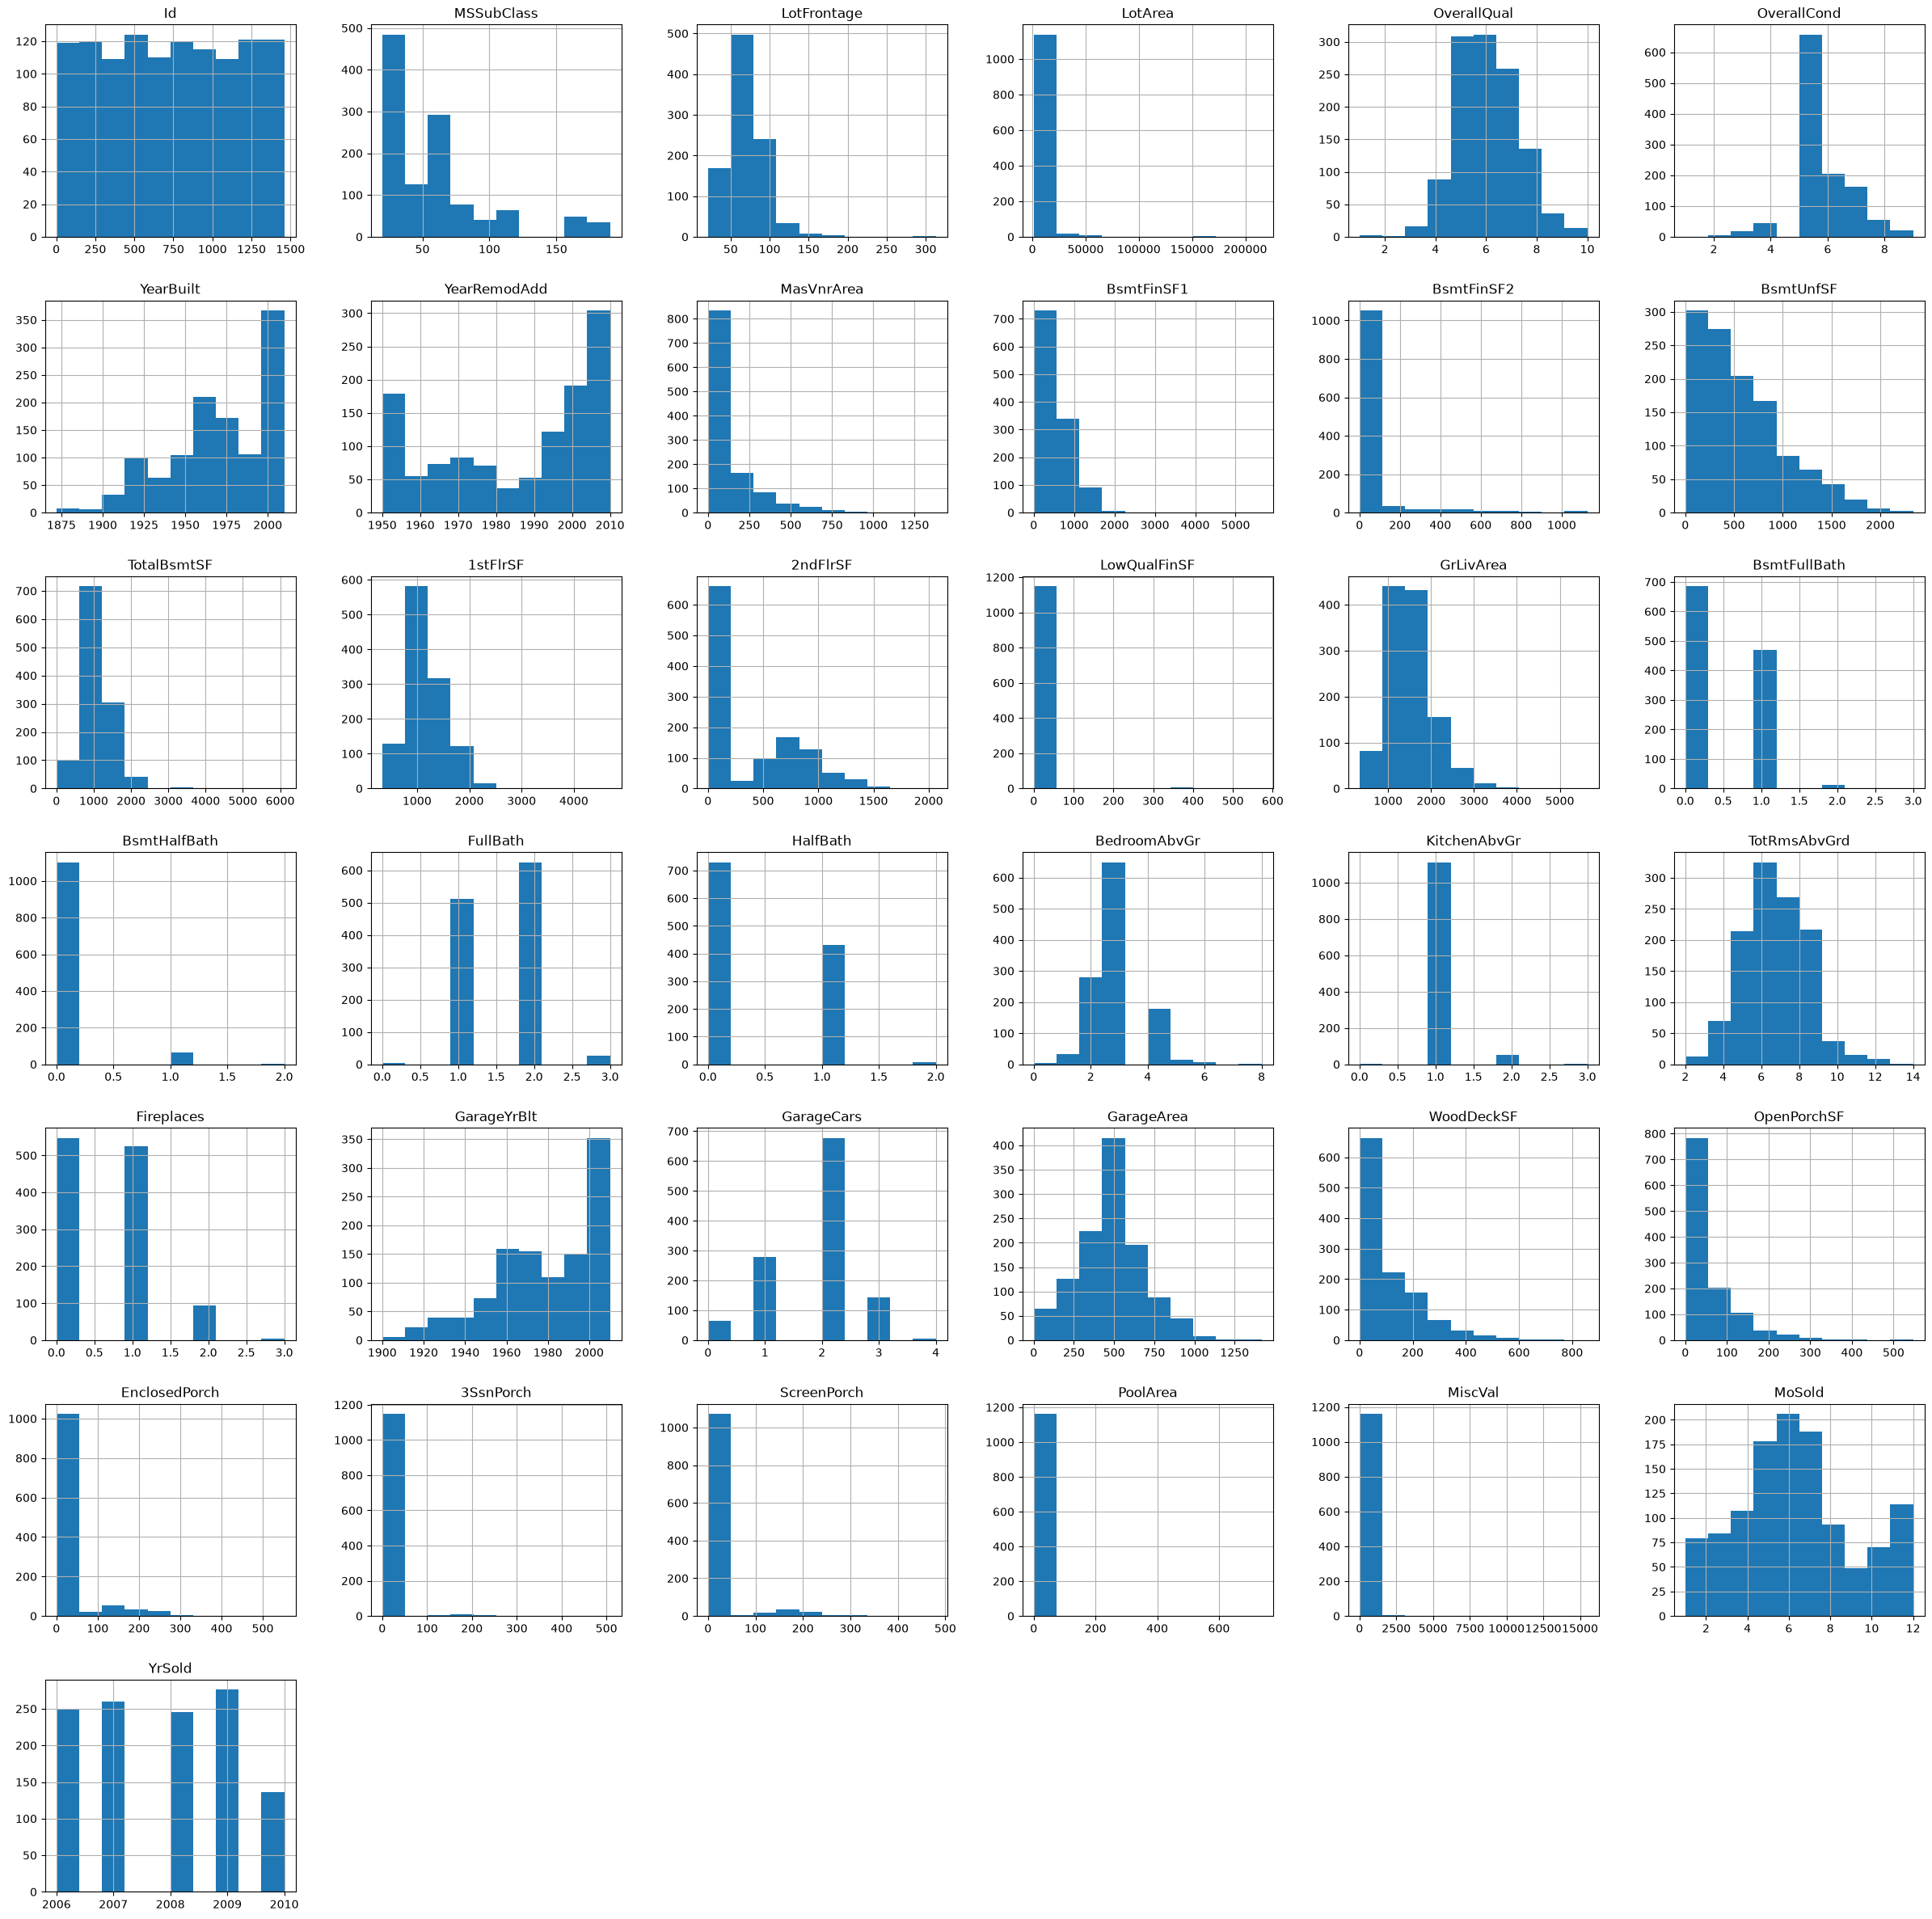

In [16]:
x_train.hist(figsize=(30,30))

In [17]:
# cat_cols = [
#     'MSZoning',
#     'Utilities',
#     'Exterior1st',
#     'Exterior2nd',
#     'Functional',
#     'SaleType'
# ]
# class CatImputer(BaseEstimator, TransformerMixin):
#     def fit(self, x, y=None):
#         self.si = SimpleImputer(strategy='most_frequent')
#         self.si.fit(x[cat_cols])
#         return self
#     def transform(self, x):
#         x = x.copy()
#         x[cat_cols] = self.si.transform(x[cat_cols])
#         return x

In [18]:
pipe = Pipeline([
    ('drop_cols', dropper()),
    ('missing_impute', MissingImputer()),
    ('num_impute', numimputer()),
    ('cat_impute', CatImputer()),
    ('rare_categories', RareCategoryGrouper()),
    ('ordinal_encode', ordinalencoder()),
    ('log_transform', LogTransformer()),
    ('one_hot_encode', OHEEncoder()),
    ('model', XGBRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    ))
])

In [19]:
param_grid = {
    'model__n_estimators': [300, 600],
    'model__max_depth': [3, 5],
    'model__learning_rate': [0.03, 0.1]
}
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)
grid.fit(x_train, y_train)
print("Best Parameters:", grid.best_params_)
print("Best CV R² Score:", grid.best_score_)
# Get the best pipeline
best_pipe = grid.best_estimator_
# Predict on test data
y_pred = best_pipe.predict(x_test)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [9, 14] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [9, 12, 13, 20] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [7, 8, 9, 14] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Foun

Best Parameters: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 600}
Best CV R² Score: 0.8958084668246


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [13, 19] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [20]:
pipe.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('drop_cols', ...), ('missing_impute', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,columns,None
Name,Type,Value
columns_,list,"['Ga...lt', 'Ma...ea', 'Bs...F1', 'Bs...F2', ...]"
imputer_,SimpleImputer,SimpleImputer...tegy='median')
Name,Type,Value
imputer_,SimpleImputer,SimpleImputer...ost_frequent')
Name,Type,Value


In [21]:
y_pred = pipe.predict(x_test)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [13, 19] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [22]:
y_pred=np.expm1(y_pred)
print("R2:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2: 0.9166756868362427
RMSE: 25280.911375976935


In [23]:
x_res=pd.read_csv('test.csv')

In [24]:
x_res

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,2915,160,RM,21.0,1936,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2006,WD,Normal
1455,2916,160,RM,21.0,1894,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2006,WD,Abnorml
1456,2917,20,RL,160.0,20000,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2006,WD,Abnorml
1457,2918,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal


In [25]:
print(set(x_train.columns) - set(x_res.columns))

set()


In [26]:
y_res=pipe.predict(x_res)

In [27]:
y_res=np.expm1(y_res)
submission = pd.DataFrame({
    'Id': range(1461, 1461 + len(y_res)),
    'SalePrice': y_res
})

submission.to_csv('xgb.csv', index=False)

In [28]:
y_res

array([126077.06, 165716.95, 181555.9 , ..., 170472.19, 112839.86,
       215387.38], shape=(1459,), dtype=float32)

In [29]:
import joblib

best_pipe = grid.best_estimator_

joblib.dump(best_pipe, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!
